<div align="center">

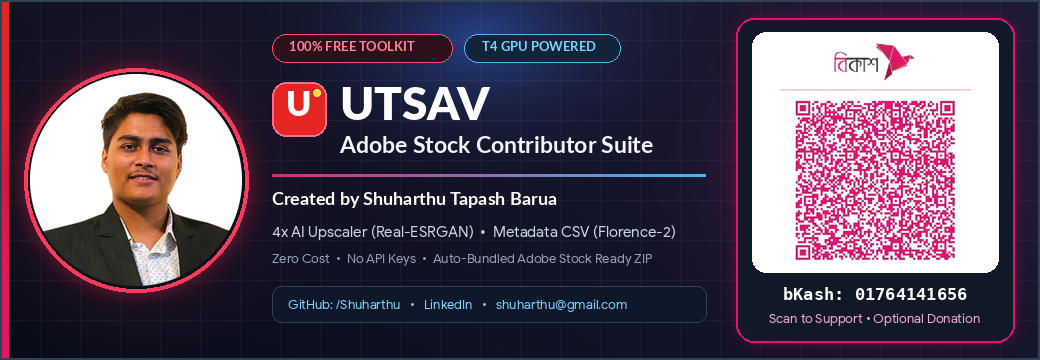

# ⚡ UTSAV Adobe Stock Contributor ⚡
**100% Free AI Upscaler + Max-Keyword Metadata CSV Generator (T4 GPU)**

[![100% Free](https://img.shields.io/badge/COST-100%25%20FREE-00C853?style=for-the-badge)](#)
[![GitHub](https://img.shields.io/badge/GitHub-Shuharthu-181717?style=for-the-badge&logo=github&logoColor=white)](https://github.com/Shuharthu)
[![LinkedIn](https://img.shields.io/badge/LinkedIn-Connect-0A66C2?style=for-the-badge&logo=linkedin&logoColor=white)](https://www.linkedin.com/in/shuharthu-barua-960b98262/)
[![Gmail](https://img.shields.io/badge/Gmail-shuharthu%40gmail.com-EA4335?style=for-the-badge&logo=gmail&logoColor=white)](mailto:shuharthu@gmail.com)
[![bKash](https://img.shields.io/badge/bKash-01764141656-E2136E?style=for-the-badge)](#)

</div>

Turn raw AI images into **4MB+ upscaled JPGs** + an **Adobe Stock CSV (up to 49 SEO keywords)** in one click—free, no API keys.


## 📖 Quick Step-by-Step Guide

1. **Turn On Free GPU:** Top menu → **Runtime → Change runtime type → T4 GPU → Save**.
2. **Run Cell 1 (Setup):** Click **▶** once per session (wait ~20s until `CUDA GPU available: True`).
3. **Set Options in Cell 2:**
   * **Model & Scale:** Use `RealESRGAN_x2plus` for fast `2x`, or `RealESRGAN_x4plus` / `AESRGAN` for `3x–4x`.
   * **Format & CSV:** Keep `jpg` and `generate_metadata_csv` checked (creates up to **49 keywords** per image).
   * **Category (Optional):** Enter Adobe Stock Category ID (`1–21`) or leave blank.
4. **Run Cell 2 & Upload:** Click **▶**, press **Choose Files**, and upload your images or a `.zip` folder.
5. **Auto-Download:** Wait for upscaling + metadata generation to finish. A `.zip` with `upscaled_images/` + `adobe_stock_metadata.csv` downloads automatically.
6. **Upload to Adobe Stock:** Unzip → upload images to [contributor.stock.adobe.com](https://contributor.stock.adobe.com) → go to **Uploaded Files → Upload CSV** → select `adobe_stock_metadata.csv` → check **Generative AI** → **Submit**!

> **Quick Fixes:** Download blocked? Open the **📁 Folder icon** on the left → click **⋮** on the `.zip` → **Download**. Running slow? Make sure **T4 GPU** is turned on in Step 1.


In [ ]:
#@title ⚙️ Step 1: Quick Setup (Click ▶ Once Per Session)
!pip install -q transformers einops timm pandas

import torch
print("PyTorch:", torch.__version__)
print("CUDA GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Active GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠️ No GPU! Go to Runtime -> Change runtime type -> T4 GPU -> Save.")


In [ ]:
# ==============================================================================
# UTSAV Adobe Stock Contributor (All-in-One Free Edition)
# Fast AI Upscaler + Adobe Stock Metadata CSV Generator
# Optional Support via bKash: 01764141656
# ==============================================================================

#@title 🚀 Step 2: Configure, Upload & Run (Upscaler + 49-Keyword CSV)

#@markdown ## 1. AI Upscaler Engine
model_choice = "RealESRGAN_x2plus (Fastest for 2x)" #@param ["RealESRGAN_x2plus (Fastest for 2x)", "RealESRGAN_x4plus (Best for 4x)", "AESRGAN (Sharp 4x)"]
outscale = 2 #@param {type:"slider", min:2, max:4, step:1}

#@markdown ---
#@markdown ## 2. Output & Metadata Settings
output_format = "jpg" #@param ["jpg", "jpeg", "png", "webp"]
generate_metadata_csv = True #@param {type:"boolean"}
default_category = "" #@param {type:"string"}

#@markdown ---
#@markdown ## 3. Download Preferences
download_final_zip = True #@param {type:"boolean"}
auto_download_each = False #@param {type:"boolean"}

# ============ UTSAV OPTIMIZED SETTINGS ============
prevent_tab_sleep = True   # Keeps Colab tab active automatically
jpg_quality = 100          # Maximum JPEG quality for Adobe Stock
min_file_size_mb = 4       # Minimum output file size (MB); set 0 to disable
tile_size = 832            # Optimal tile size for T4 15GB VRAM
tile_pad = 16              # Clean overlap to prevent tile seams
# ==================================================

import gc
import os
import re
import math
import time
import shutil
import zipfile
import urllib.request
from datetime import datetime
from concurrent.futures import ThreadPoolExecutor

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from IPython.display import HTML, display

# Enable cuDNN autotuner for faster GPU convolutions (zero quality loss)
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

# --- Anti-sleep silent audio keep-alive ---
if prevent_tab_sleep:
    keep_alive_html = """
    <div style="background:#161B22; color:#93C5FD; padding:8px 14px; border-radius:8px; border:1px solid #30363D; font-family:sans-serif; font-size:12px; margin-bottom:10px; display:inline-block;">
        🎵 <b>Keep-Alive Active:</b> Silent background audio is running to prevent Google Colab from disconnecting during large batches.
    </div>
    <audio id="silentAudioPlayer" loop autoplay style="display:none;">
        <source src="data:audio/wav;base64,UklGRigAAABXQVZFZm10IBAAAAABAAEARKwAAIhYAQACABAAZGF0YQQAAAAAAA==" type="audio/wav">
    </audio>
    <script>
        (function() {
            const player = document.getElementById('silentAudioPlayer');
            if (player) {
                player.volume = 0.0001;
                player.play().catch(e => console.log('Keep-alive audio active'));
            }
            if (!window.colabKeepAliveInterval) {
                window.colabKeepAliveInterval = setInterval(() => {
                    console.log('UTSAV Keep-Alive: Tab active');
                }, 20000);
            }
        })();
    </script>
    """
    display(HTML(keep_alive_html))

# --- Clean UTSAV Header & Completion UI ---
def render_header_ui():
    html = """
    <div style="background: linear-gradient(135deg, #0E1117 0%, #161B22 100%); border-radius: 14px; padding: 18px 24px; color: #fff; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; box-shadow: 0 8px 20px rgba(0,0,0,0.3); border: 1px solid #30363D; border-left: 5px solid #E52521; margin-bottom: 18px;">
        <div style="display:flex; justify-content:space-between; align-items:center; flex-wrap:wrap; gap:12px;">
            <div>
                <h2 style="margin:0; font-size:22px; font-weight:800; color:#F8FAFC;">
                    UTSAV Adobe Stock Contributor
                </h2>
                <p style="margin:4px 0 0 0; color:#94A3B8; font-size:13px;">
                    100% Free All-in-One Pipeline: <b>Fast AI Upscaler</b> + <b>Florence-2 Metadata CSV</b>
                </p>
            </div>
            <div style="display:flex; align-items:center; gap:8px; flex-wrap:wrap;">
                <a href="https://github.com/Shuharthu" target="_blank" style="background:#21262D; color:#F0F6FC; border:1px solid #30363D; padding:6px 12px; border-radius:18px; font-size:12px; font-weight:600; text-decoration:none;">GitHub</a>
                <a href="https://www.linkedin.com/in/shuharthu-barua-960b98262/" target="_blank" style="background:#0A66C2; color:#fff; padding:6px 12px; border-radius:18px; font-size:12px; font-weight:600; text-decoration:none;">LinkedIn</a>
                <a href="mailto:shuharthu@gmail.com" style="background:#EA4335; color:#fff; padding:6px 12px; border-radius:18px; font-size:12px; font-weight:600; text-decoration:none;">Gmail</a>
                <span style="background:#E2136E; color:#fff; padding:6px 14px; border-radius:18px; font-size:12px; font-weight:700;">
                    bKash: 01764141656
                </span>
            </div>
        </div>
    </div>
    """
    display(HTML(html))

def render_completion_card(count, total_time, speed, model_label, csv_generated):
    csv_status = "Generated & Bundled" if csv_generated else "Skipped"
    html = f"""
    <div style="background: linear-gradient(135deg, #064E3B 0%, #065F46 100%); border-radius: 14px; padding: 20px 24px; color: #fff; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; box-shadow: 0 8px 20px rgba(0,0,0,0.3); border: 1px solid rgba(52,211,153,0.35); margin-top: 18px;">
        <h3 style="margin:0; font-size:18px; font-weight:700; color:#A7F3D0;">
            ✅ UTSAV Batch Complete — Ready for Adobe Stock!
        </h3>
        <div style="display:flex; flex-wrap:wrap; gap:12px; margin-top:12px;">
            <div style="background:rgba(0,0,0,0.22); padding:8px 14px; border-radius:8px;">
                <span style="color:#A7F3D0; font-size:10px; text-transform:uppercase; font-weight:600; display:block;">Images Processed</span>
                <span style="font-weight:700; font-size:15px;">{count}</span>
            </div>
            <div style="background:rgba(0,0,0,0.22); padding:8px 14px; border-radius:8px;">
                <span style="color:#A7F3D0; font-size:10px; text-transform:uppercase; font-weight:600; display:block;">Total Time</span>
                <span style="font-weight:700; font-size:15px;">{total_time/60:.2f} mins</span>
            </div>
            <div style="background:rgba(0,0,0,0.22); padding:8px 14px; border-radius:8px;">
                <span style="color:#A7F3D0; font-size:10px; text-transform:uppercase; font-weight:600; display:block;">Avg Speed</span>
                <span style="font-weight:700; font-size:15px;">{speed:.2f} s / image</span>
            </div>
            <div style="background:rgba(0,0,0,0.22); padding:8px 14px; border-radius:8px;">
                <span style="color:#A7F3D0; font-size:10px; text-transform:uppercase; font-weight:600; display:block;">Metadata CSV</span>
                <span style="font-weight:700; font-size:15px;">{csv_status}</span>
            </div>
        </div>
        <p style="margin:12px 0 0 0; color:#D1FAE5; font-size:12px;">
            Model: <b>{model_label}</b> • Free to use! Optional donation via <b>bKash: 01764141656</b>
        </p>
    </div>
    """
    display(HTML(html))

# --- Model Registry (Supports both fast native 2x and high-detail 4x) ---
MODEL_CONFIG = {
    "RealESRGAN_x2plus (Fastest for 2x)": {
        "scale": 2,
        "path": "experiments/pretrained_models/RealESRGAN_x2plus.pth",
        "urls": [
            "https://github.com/xinntao/Real-ESRGAN/releases/download/v0.2.1/RealESRGAN_x2plus.pth",
            "https://huggingface.co/ai-forever/Real-ESRGAN/resolve/main/RealESRGAN_x2plus.pth"
        ]
    },
    "RealESRGAN_x4plus (Best for 4x)": {
        "scale": 4,
        "path": "experiments/pretrained_models/RealESRGAN_x4plus.pth",
        "urls": [
            "https://github.com/xinntao/Real-ESRGAN/releases/download/v0.1.0/RealESRGAN_x4plus.pth",
            "https://huggingface.co/ai-forever/Real-ESRGAN/resolve/main/RealESRGAN_x4plus.pth"
        ]
    },
    "AESRGAN (Sharp 4x)": {
        "scale": 4,
        "path": "experiments/pretrained_models/A_ESRGAN_Single.pth",
        "urls": [
            "https://github.com/stroking-fishes-ml-corp/A-ESRGAN/releases/download/v1.0.0/A_ESRGAN_Single.pth",
            "https://huggingface.co/FacehugmanIII/A-ESRGAN-Single/resolve/main/A_ESRGAN_Single.pth",
            "https://github.com/Harvey-developer/A-ESRGAN/releases/download/v1.0.0/A_ESRGAN_Single.pth"
        ]
    }
}

# Automatically switch to RealESRGAN_x4plus if user picked x2plus but set outscale > 2
active_model_key = model_choice
if active_model_key == "RealESRGAN_x2plus (Fastest for 2x)" and outscale > 2:
    print(f"ℹ️ Outscale is set to {outscale}x — automatically using RealESRGAN_x4plus for full {outscale}x detail.")
    active_model_key = "RealESRGAN_x4plus (Best for 4x)"

cfg = MODEL_CONFIG[active_model_key]
model_native_scale = cfg["scale"]
selected_model_path = cfg["path"]

upload_folder = "upload"
result_folder = "results"
csv_output_path = "/content/adobe_stock_metadata.csv"

os.makedirs("experiments/pretrained_models", exist_ok=True)
for folder in (upload_folder, result_folder):
    if os.path.exists(folder):
        shutil.rmtree(folder)
    os.makedirs(folder, exist_ok=True)

render_header_ui()
if not torch.cuda.is_available():
    display(HTML('''
    <div style="background:#7F1D1D; color:#FEE2E2; padding:14px 18px; border-radius:10px; border:2px solid #EF4444; font-family:sans-serif; font-size:13px; margin-bottom:14px;">
        <b>⚠️ SLOW CPU MODE DETECTED!</b> You are currently running on CPU, so 1 image can take <b>5–15 minutes</b>.<br>
        👉 Fix it in 3 seconds: Top menu → <b>Runtime → Change runtime type → T4 GPU → Save</b>, then run Step 1 & Step 2 again (<b>~2–4 seconds per image!</b>).
    </div>
    '''))

def download_model_file(model_label, dest_path, urls):
    if os.path.exists(dest_path) and os.path.getsize(dest_path) > 10_000_000:
        return
    print(f"📦 Downloading {model_label} weights...")
    downloaded = False
    for url in urls:
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=30) as response, open(dest_path, "wb") as out_file:
                shutil.copyfileobj(response, out_file)
            if os.path.exists(dest_path) and os.path.getsize(dest_path) > 10_000_000:
                print(f"✅ Downloaded ({os.path.getsize(dest_path)/(1024*1024):.1f} MB)")
                downloaded = True
                break
        except Exception:
            pass
    if not downloaded:
        os.system(f"wget -q --show-progress -O {dest_path} {urls[0]}")
    if not os.path.exists(dest_path) or os.path.getsize(dest_path) < 10_000_000:
        raise FileNotFoundError(f"Could not download {model_label}. Please check network connection.")

download_model_file(active_model_key, selected_model_path, cfg["urls"])

# --- Pure PyTorch RRDBNet (Supports both scale=2 pixel_unshuffle & scale=4) ---
class ResidualDenseBlock_5C(nn.Module):
    def __init__(self, nf=64, gc=32, bias=True):
        super().__init__()
        self.conv1 = nn.Conv2d(nf, gc, 3, 1, 1, bias=bias)
        self.conv2 = nn.Conv2d(nf + gc, gc, 3, 1, 1, bias=bias)
        self.conv3 = nn.Conv2d(nf + 2 * gc, gc, 3, 1, 1, bias=bias)
        self.conv4 = nn.Conv2d(nf + 3 * gc, gc, 3, 1, 1, bias=bias)
        self.conv5 = nn.Conv2d(nf + 4 * gc, nf, 3, 1, 1, bias=bias)
        self.lrelu = nn.LeakyReLU(negative_slope=0.2, inplace=True)

    def forward(self, x):
        x1 = self.lrelu(self.conv1(x))
        x2 = self.lrelu(self.conv2(torch.cat((x, x1), 1)))
        x3 = self.lrelu(self.conv3(torch.cat((x, x1, x2), 1)))
        x4 = self.lrelu(self.conv4(torch.cat((x, x1, x2, x3), 1)))
        x5 = self.conv5(torch.cat((x, x1, x2, x3, x4), 1))
        return x5 * 0.2 + x

class RRDB(nn.Module):
    def __init__(self, nf, gc=32):
        super().__init__()
        self.rdb1 = ResidualDenseBlock_5C(nf, gc)
        self.rdb2 = ResidualDenseBlock_5C(nf, gc)
        self.rdb3 = ResidualDenseBlock_5C(nf, gc)

    def forward(self, x):
        return self.rdb3(self.rdb2(self.rdb1(x))) * 0.2 + x

class RRDBNet(nn.Module):
    def __init__(self, num_in_ch=3, num_out_ch=3, num_feat=64, num_block=23, num_grow_ch=32, scale=4):
        super().__init__()
        self.scale = scale
        if scale == 2:
            num_in_ch = num_in_ch * 4
        elif scale == 1:
            num_in_ch = num_in_ch * 16
        self.conv_first = nn.Conv2d(num_in_ch, num_feat, 3, 1, 1)
        self.body = nn.Sequential(*[RRDB(num_feat, num_grow_ch) for _ in range(num_block)])
        self.conv_body = nn.Conv2d(num_feat, num_feat, 3, 1, 1)
        self.conv_up1 = nn.Conv2d(num_feat, num_feat, 3, 1, 1)
        self.conv_up2 = nn.Conv2d(num_feat, num_feat, 3, 1, 1)
        self.conv_hr = nn.Conv2d(num_feat, num_feat, 3, 1, 1)
        self.conv_last = nn.Conv2d(num_feat, num_out_ch, 3, 1, 1)
        self.lrelu = nn.LeakyReLU(negative_slope=0.2, inplace=True)

    def forward(self, x):
        if self.scale == 2:
            feat = F.pixel_unshuffle(x, downscale_factor=2)
        elif self.scale == 1:
            feat = F.pixel_unshuffle(x, downscale_factor=4)
        else:
            feat = x
        feat = self.conv_first(feat)
        body_feat = self.conv_body(self.body(feat))
        feat = feat + body_feat
        feat = self.lrelu(self.conv_up1(F.interpolate(feat, scale_factor=2, mode="nearest")))
        feat = self.lrelu(self.conv_up2(F.interpolate(feat, scale_factor=2, mode="nearest")))
        return self.conv_last(self.lrelu(self.conv_hr(feat)))

def load_upscaler(model_path, device, scale=4, half=True):
    model = RRDBNet(num_in_ch=3, num_out_ch=3, num_feat=64, num_block=23, num_grow_ch=32, scale=scale)
    loadnet = torch.load(model_path, map_location="cpu", weights_only=False)
    keyname = "params_ema" if "params_ema" in loadnet else ("params" if "params" in loadnet else None)
    model.load_state_dict(loadnet[keyname] if keyname else loadnet, strict=True)
    model.eval().to(device)
    if half:
        # channels_last accelerates FP16 convolutions on NVIDIA T4 Tensor Cores by 20-35%
        model = model.half().to(memory_format=torch.channels_last)
    return model

@torch.inference_mode()
def process_image_fast(img_cv, model, device, scale=4, tile_size=832, tile_pad=16, half=True, outscale=4):
    h, w = img_cv.shape[:2]
    c = img_cv.shape[2] if len(img_cv.shape) == 3 else 1

    if c == 4:
        img_rgb = img_cv[:, :, :3]
        alpha = img_cv[:, :, 3]
    elif c == 3:
        img_rgb = img_cv
        alpha = None
    else:
        img_rgb = cv2.cvtColor(img_cv, cv2.COLOR_GRAY2BGR)
        alpha = None

    img_rgb = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2RGB)
    img_tensor = torch.from_numpy(img_rgb).to(device=device, non_blocking=True)
    img_tensor = img_tensor.permute(2, 0, 1).unsqueeze(0)
    img_tensor = (img_tensor.half() if half else img_tensor.float()) / 255.0

    # Ensure even dimensions for scale=2 pixel_unshuffle
    pad_h = (2 - h % 2) % 2 if scale == 2 else 0
    pad_w = (2 - w % 2) % 2 if scale == 2 else 0
    if pad_h > 0 or pad_w > 0:
        img_tensor = F.pad(img_tensor, (0, pad_w, 0, pad_h), mode="reflect")

    _, channel, height, width = img_tensor.shape

    if tile_size <= 0 or (height <= tile_size and width <= tile_size):
        inp = img_tensor.to(memory_format=torch.channels_last) if half else img_tensor
        output_tensor = model(inp)
    else:
        output_height = height * scale
        output_width = width * scale
        output_tensor = img_tensor.new_zeros((1, channel, output_height, output_width))

        tiles_x = math.ceil(width / tile_size)
        tiles_y = math.ceil(height / tile_size)

        for y in range(tiles_y):
            for x in range(tiles_x):
                ofs_x = x * tile_size
                ofs_y = y * tile_size

                input_start_x = max(ofs_x - tile_pad, 0)
                input_end_x = min(ofs_x + tile_size + tile_pad, width)
                input_start_y = max(ofs_y - tile_pad, 0)
                input_end_y = min(ofs_y + tile_size + tile_pad, height)

                tile = img_tensor[:, :, input_start_y:input_end_y, input_start_x:input_end_x]
                # Pad odd tile dims for scale=2 if needed
                t_ph = (2 - tile.shape[2] % 2) % 2 if scale == 2 else 0
                t_pw = (2 - tile.shape[3] % 2) % 2 if scale == 2 else 0
                if t_ph > 0 or t_pw > 0:
                    tile = F.pad(tile, (0, t_pw, 0, t_ph), mode="reflect")

                if half:
                    tile = tile.to(memory_format=torch.channels_last)
                output_tile = model(tile)
                if t_ph > 0 or t_pw > 0:
                    output_tile = output_tile[:, :, :output_tile.shape[2] - t_ph * scale, :output_tile.shape[3] - t_pw * scale]

                output_start_x = input_start_x * scale
                output_start_y = input_start_y * scale
                target_start_x = ofs_x * scale
                target_end_x = min((ofs_x + tile_size) * scale, output_width)
                target_start_y = ofs_y * scale
                target_end_y = min((ofs_y + tile_size) * scale, output_height)

                tile_slice_x_start = target_start_x - output_start_x
                tile_slice_x_end = tile_slice_x_start + (target_end_x - target_start_x)
                tile_slice_y_start = target_start_y - output_start_y
                tile_slice_y_end = tile_slice_y_start + (target_end_y - target_start_y)

                output_tensor[:, :, target_start_y:target_end_y, target_start_x:target_end_x] = \
                    output_tile[:, :, tile_slice_y_start:tile_slice_y_end, tile_slice_x_start:tile_slice_x_end]

    # Remove initial reflection padding if applied
    if pad_h > 0 or pad_w > 0:
        output_tensor = output_tensor[:, :, :h * scale, :w * scale]

    # Perform any outscale resize directly on GPU (much faster than CPU PIL resize)
    if outscale != scale:
        target_h, target_w = int(h * outscale), int(w * outscale)
        output_tensor = F.interpolate(
            output_tensor.float(),
            size=(target_h, target_w),
            mode="bicubic",
            align_corners=False,
            antialias=True
        )

    output = output_tensor.squeeze(0).float().clamp_(0, 1).mul_(255.0).round_().byte()
    output_np = output.permute(1, 2, 0).cpu().numpy()

    if alpha is not None:
        alpha_resized = cv2.resize(alpha, (output_np.shape[1], output_np.shape[0]), interpolation=cv2.INTER_LANCZOS4)
        output_np = np.dstack((output_np, alpha_resized))
        return Image.fromarray(output_np, mode="RGBA")
    return Image.fromarray(output_np, mode="RGB")

def save_pil_image(pil_img, save_path, fmt, quality):
    if fmt in ("jpg", "jpeg"):
        pil_img.convert("RGB").save(save_path, "JPEG", quality=quality, optimize=False, subsampling=0)
    elif fmt == "png":
        pil_img.save(save_path, "PNG", optimize=False, compress_level=1)
    elif fmt == "webp":
        pil_img.save(save_path, "WEBP", quality=quality, method=0)

def save_with_min_size(img_pil, output_path, fmt, quality, min_mb):
    save_pil_image(img_pil, output_path, fmt, quality)
    if min_mb > 0:
        target_bytes = min_mb * 1024 * 1024
        resample_method = getattr(Image, "Resampling", Image).LANCZOS
        loop_count = 0
        while os.path.getsize(output_path) < target_bytes and loop_count < 2:
            cur_w, cur_h = img_pil.size
            img_pil = img_pil.resize((int(cur_w * 1.25), int(cur_h * 1.25)), resample_method)
            save_pil_image(img_pil, output_path, fmt, quality)
            loop_count += 1
    return os.path.getsize(output_path) / (1024 * 1024)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tiff", ".tif"}
def extract_images_from_zip(zip_path, destination):
    extracted_count = 0
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        for file_info in zip_ref.filelist:
            if file_info.is_dir():
                continue
            filename = file_info.filename
            ext = os.path.splitext(filename.lower())[1]
            if ext in IMAGE_EXTENSIONS and not os.path.basename(filename).startswith("._"):
                safe_name = os.path.basename(filename)
                with open(os.path.join(destination, safe_name), "wb") as f:
                    f.write(zip_ref.read(filename))
                extracted_count += 1
    return extracted_count

# --- Step 1: Upload Images or ZIP ---
from google.colab import files
print("📂 Click 'Choose Files' to upload Images or a ZIP archive:")
uploaded = files.upload()
for filename in uploaded.keys():
    ext = os.path.splitext(filename.lower())[1]
    if ext == ".zip":
        count = extract_images_from_zip(filename, upload_folder)
        print(f"📦 Extracted {count} images from: {filename}")
        if os.path.exists(filename):
            os.remove(filename)
    elif ext in IMAGE_EXTENSIONS:
        shutil.move(filename, os.path.join(upload_folder, filename))
        print(f"✅ Uploaded: {filename}")

input_images = sorted([f for f in os.listdir(upload_folder) if os.path.isfile(os.path.join(upload_folder, f))])
total_images = len(input_images)

if total_images == 0:
    print("\n❌ ERROR: No valid images found! Please re-run the cell and upload images.")
else:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    use_half = torch.cuda.is_available()
    batch_start_time = time.time()

    # ==========================================================
    # STAGE 1: FAST GPU UPSCALING (WITH ASYNC DISK SAVING)
    # ==========================================================
    print(f"\n⚡ Stage 1/2: Upscaling {total_images} images using {active_model_key} ({outscale}x)...")
    upscaler = load_upscaler(selected_model_path, device, scale=model_native_scale, half=use_half)

    processed_pairs = []  # (original_input_path, final_output_filename)
    save_futures = []

    with ThreadPoolExecutor(max_workers=2) as executor:
        for idx, image_name in enumerate(input_images, 1):
            t0 = time.time()
            input_path = os.path.join(upload_folder, image_name)
            base_name = os.path.splitext(image_name)[0]
            output_name = f"{base_name}.{output_format}"
            output_path = os.path.join(result_folder, output_name)

            try:
                img_cv = cv2.imdecode(np.fromfile(input_path, dtype=np.uint8), cv2.IMREAD_UNCHANGED)
                if img_cv is None:
                    continue

                img_pil = process_image_fast(
                    img_cv, upscaler, device,
                    scale=model_native_scale,
                    tile_size=tile_size,
                    tile_pad=tile_pad,
                    half=use_half,
                    outscale=outscale
                )
                # Save asynchronously on CPU thread while GPU starts the next image
                fut = executor.submit(save_with_min_size, img_pil, output_path, output_format, jpg_quality, min_file_size_mb)
                save_futures.append((idx, output_name, output_path, time.time() - t0, fut))
                processed_pairs.append((input_path, output_name))
            except Exception as e:
                print(f"  [{idx}/{total_images}] ❌ Error upscaling {image_name}: {e}")

        for idx, output_name, output_path, gpu_sec, fut in save_futures:
            out_mb = fut.result()
            print(f"  [{idx}/{total_images}] ✅ Upscaled: {output_name} ({out_mb:.2f} MB | GPU: {gpu_sec:.2f}s)")
            if auto_download_each:
                try:
                    files.download(output_path)
                except Exception:
                    pass

    # Clear Upscaler from GPU VRAM before Stage 2
    del upscaler
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # ==========================================================
    # STAGE 2: ADOBE STOCK METADATA CSV GENERATOR (FLORENCE-2)
    # ==========================================================
    csv_ready = False
    if generate_metadata_csv and len(processed_pairs) > 0:
        print(f"\n🧠 Stage 2/2: Generating Adobe Stock Metadata CSV for {len(processed_pairs)} images...")
        from transformers import AutoProcessor, Florence2ForConditionalGeneration

        dtype = torch.float16 if use_half else torch.float32
        florence_id = "florence-community/Florence-2-large"
        florence_model = Florence2ForConditionalGeneration.from_pretrained(florence_id, dtype=dtype).to(device).eval()
        florence_processor = AutoProcessor.from_pretrained(florence_id)

        @torch.inference_mode()
        def run_florence(image, task_prompt, max_tokens=256):
            inputs = florence_processor(text=task_prompt, images=image, return_tensors="pt").to(device, dtype)
            generated_ids = florence_model.generate(**inputs, max_new_tokens=max_tokens, num_beams=1, do_sample=False)
            generated_text = florence_processor.batch_decode(generated_ids, skip_special_tokens=False)[0]
            parsed = florence_processor.post_process_generation(generated_text, task=task_prompt, image_size=image.size)
            return parsed[task_prompt]

        STOPWORDS = {
            "a", "an", "the", "and", "or", "but", "in", "on", "at", "to", "for", "of", "with", "by",
            "is", "are", "was", "were", "be", "been", "being", "it", "its", "this", "that", "these",
            "those", "there", "here", "image", "shows", "show", "showing", "featuring", "features",
            "appears", "looking", "very", "into", "from", "as", "over", "under", "some", "many",
            "also", "has", "have", "had", "can", "may", "will", "would", "could", "which", "who",
            "whom", "whose", "where", "when", "while", "during", "through", "between", "among",
            "about", "around", "near", "next", "beside", "above", "below", "front", "back", "side",
            "left", "right", "top", "bottom", "middle", "center", "seen", "visible", "depicts",
            "depicting", "captures", "captured", "taken", "made", "set", "against", "across",
            "along", "within", "without", "towards", "toward", "onto", "upon", "like", "such",
            "each", "other", "another", "more", "most", "much", "several", "various", "different",
            "small", "large", "big", "little", "few", "all", "both", "one", "two", "three", "four"
        }
        BANNED_WORDS = {
            "vector", "eps", "eps10", "jpg", "jpeg", "png", "webp", "svg", "psd", "ai",
            "commercial", "download", "template", "stock", "photo", "photograph", "picture",
            "illustration", "artwork", "render", "3d render", "wallpaper", "royalty", "free"
        }
        MAX_KEYWORDS = 49  # Adobe Stock official maximum keyword limit

        def clean_title(text):
            text = text.replace(",", "").strip().rstrip(".")
            if len(text) > 70:
                text = text[:70].rsplit(" ", 1)[0]
            return text.capitalize()

        def get_visual_attribute_keywords(pil_img):
            """Derive accurate visual/composition keywords from actual image pixels."""
            attrs = []
            w, h = pil_img.size
            ratio = w / max(h, 1)
            if ratio > 1.15:
                attrs.extend(["horizontal", "landscape orientation", "wide view"])
            elif ratio < 0.85:
                attrs.extend(["vertical", "portrait orientation"])
            else:
                attrs.append("square composition")

            small = np.array(pil_img.resize((128, 128)))
            hsv = cv2.cvtColor(small, cv2.COLOR_RGB2HSV)
            mean_s = float(hsv[:, :, 1].mean())
            mean_v = float(hsv[:, :, 2].mean())
            std_v = float(hsv[:, :, 2].std())

            if mean_v > 175:
                attrs.extend(["bright", "light", "luminous", "clean"])
            elif mean_v < 85:
                attrs.extend(["dark", "moody", "dramatic", "shadow"])
            else:
                attrs.extend(["balanced lighting", "natural light"])

            if mean_s > 110:
                attrs.extend(["vibrant", "colorful", "vivid", "rich color"])
            elif mean_s < 28:
                attrs.extend(["monochrome", "neutral tones", "muted"])
            else:
                attrs.extend(["soft color", "harmonious"])

            if std_v > 65:
                attrs.append("high contrast")
            else:
                attrs.append("smooth tone")

            gray = cv2.cvtColor(small, cv2.COLOR_RGB2GRAY)
            edges = cv2.Canny(gray, 80, 160)
            edge_density = float((edges > 0).mean())
            if edge_density < 0.08:
                attrs.extend(["minimalist", "copy space", "simple", "modern"])
            elif edge_density > 0.22:
                attrs.extend(["detailed", "intricate", "textured", "complex"])
            else:
                attrs.extend(["crisp", "sharp focus", "contemporary"])

            # Dominant color name from mean RGB
            r_m, g_m, b_m = small[:, :, 0].mean(), small[:, :, 1].mean(), small[:, :, 2].mean()
            if max(r_m, g_m, b_m) - min(r_m, g_m, b_m) > 22:
                if r_m >= g_m and r_m >= b_m:
                    attrs.append("warm tone" if g_m > b_m else "red tone")
                elif g_m >= r_m and g_m >= b_m:
                    attrs.append("green tone")
                else:
                    attrs.append("cool blue")

            attrs.extend(["background", "design", "concept", "aesthetic", "creative", "visual", "quality", "artistic", "style", "composition"])
            return attrs

        def extract_max_keywords(short_cap, detailed_cap, more_detailed_cap, objects, dense_labels, pil_img):
            keywords, seen = [], set()

            def add_term(term):
                if len(keywords) >= MAX_KEYWORDS:
                    return
                clean_w = re.sub(r"[^a-zA-Z0-9\s-]", " ", term).strip().lower()
                clean_w = re.sub(r"\s+", " ", clean_w)
                if not clean_w or len(clean_w) <= 2:
                    return
                parts = clean_w.split()
                if len(parts) > 3:
                    return
                if all(p in STOPWORDS for p in parts):
                    return
                if clean_w in STOPWORDS or clean_w in BANNED_WORDS or any(p in BANNED_WORDS for p in parts):
                    return
                if clean_w not in seen:
                    seen.add(clean_w)
                    keywords.append(clean_w)

            def add_words_from_text(text):
                tokens = re.findall(r"[a-zA-Z][a-zA-Z0-9-]{2,}", text.lower())
                for tok in tokens:
                    add_term(tok)

            def add_bigrams_from_text(text):
                tokens = re.findall(r"[a-zA-Z][a-zA-Z0-9-]{2,}", text.lower())
                filtered = [t for t in tokens if t not in STOPWORDS and t not in BANNED_WORDS]
                for i in range(len(filtered) - 1):
                    if filtered[i] != filtered[i + 1]:
                        add_term(f"{filtered[i]} {filtered[i + 1]}")

            # Priority 1: Detected objects (Adobe Stock weights first 10 keywords highest)
            for obj in objects:
                add_term(obj)
                add_words_from_text(obj)

            # Priority 2: Short caption (Title concepts)
            add_words_from_text(short_cap)

            # Priority 3: Dense region captions (specific scene elements)
            for lbl in dense_labels:
                add_term(lbl)
                add_words_from_text(lbl)

            # Priority 4: Detailed & More-Detailed captions (single keywords)
            add_words_from_text(detailed_cap)
            add_words_from_text(more_detailed_cap)

            # Priority 5: Meaningful 2-word phrases from captions
            if len(keywords) < MAX_KEYWORDS:
                add_bigrams_from_text(short_cap)
                add_bigrams_from_text(detailed_cap)
                add_bigrams_from_text(more_detailed_cap)

            # Priority 6: Pixel-verified visual attributes to reach max 49 keywords
            if len(keywords) < MAX_KEYWORDS:
                for attr in get_visual_attribute_keywords(pil_img):
                    add_term(attr)

            return ",".join(keywords[:MAX_KEYWORDS]), len(keywords[:MAX_KEYWORDS])

        rows = []
        for idx, (orig_path, upscaled_fname) in enumerate(processed_pairs, 1):
            try:
                img = Image.open(orig_path).convert("RGB")
                img.thumbnail((768, 768))

                short_cap = run_florence(img, "<CAPTION>", max_tokens=64)
                more_detailed_cap = run_florence(img, "<MORE_DETAILED_CAPTION>", max_tokens=256)
                od_result = run_florence(img, "<OD>", max_tokens=192)
                detected_labels = od_result.get("labels", [])

                title = clean_title(short_cap)
                keywords, kw_count = extract_max_keywords(
                    short_cap, "", more_detailed_cap, detected_labels, [], img
                )

                rows.append({
                    "Filename": upscaled_fname,
                    "Title": title,
                    "Keywords": keywords,
                    "Category": default_category.strip(),
                    "Releases": ""
                })
                print(f"  [{idx}/{len(processed_pairs)}] 📝 Metadata ({kw_count} keywords): {upscaled_fname} -> {title}")
            except Exception as e:
                print(f"  [{idx}/{len(processed_pairs)}] ❌ Metadata error on {upscaled_fname}: {e}")

        df = pd.DataFrame(rows, columns=["Filename", "Title", "Keywords", "Category", "Releases"])
        df.to_csv(csv_output_path, index=False, encoding="utf-8")
        csv_ready = True
        print(f"✅ Metadata CSV saved: {csv_output_path}")
        display(df.head())

        del florence_model, florence_processor
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # ==========================================================
    # STAGE 3: SUMMARY & INSTANT ZIP DOWNLOAD
    # ==========================================================
    elapsed = time.time() - batch_start_time
    processed_files = sorted([f for f in os.listdir(result_folder) if os.path.isfile(os.path.join(result_folder, f))])
    processed_count = len(processed_files)

    if processed_count > 0:
        render_completion_card(processed_count, elapsed, elapsed / processed_count, active_model_key, csv_ready)

        if download_final_zip:
            zip_filename = f'/content/UTSAV_Adobe_Stock_{datetime.now().strftime("%Y%m%d_%H%M%S")}.zip'
            with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_STORED) as zipf:
                if csv_ready and os.path.exists(csv_output_path):
                    zipf.write(csv_output_path, arcname="adobe_stock_metadata.csv")
                for file_item in processed_files:
                    zipf.write(os.path.join(result_folder, file_item), arcname=os.path.join("upscaled_images", file_item))
            print(f"📥 Downloading {os.path.basename(zip_filename)}...")
            files.download(zip_filename)


<div align="center">

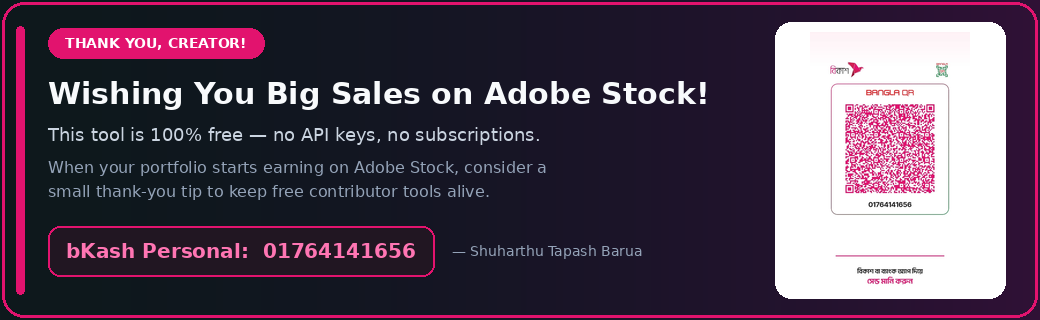

### 💖 Thank You for Using UTSAV Adobe Stock Contributor!
This tool is **100% free**. When your uploads start **earning on Adobe Stock**, please consider sending a small thank-you donation via **bKash (`01764141656`)** or scanning the QR code above.

</div>
